In [1]:
import pandas as pd

In [2]:
df= pd.read_csv(r'F:\Fiels Course Data Analysis\ملف مشروع النهائي كورونا(للمبرمجين)\data.csv')

In [4]:
df.head(5)

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2019,continentExp,Cumulative_number_for_14_days_of_COVID-19_cases_per_100000
0,14/12/2020,14,12,2020,746,6,Afghanistan,AF,AFG,38041757.0,Asia,9.013779
1,13/12/2020,13,12,2020,298,9,Afghanistan,AF,AFG,38041757.0,Asia,7.052776
2,12/12/2020,12,12,2020,113,11,Afghanistan,AF,AFG,38041757.0,Asia,6.868768
3,11/12/2020,11,12,2020,63,10,Afghanistan,AF,AFG,38041757.0,Asia,7.134266
4,10/12/2020,10,12,2020,202,16,Afghanistan,AF,AFG,38041757.0,Asia,6.968658


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61900 entries, 0 to 61899
Data columns (total 12 columns):
 #   Column                                                      Non-Null Count  Dtype  
---  ------                                                      --------------  -----  
 0   dateRep                                                     61900 non-null  object 
 1   day                                                         61900 non-null  int64  
 2   month                                                       61900 non-null  int64  
 3   year                                                        61900 non-null  int64  
 4   cases                                                       61900 non-null  int64  
 5   deaths                                                      61900 non-null  int64  
 6   countriesAndTerritories                                     61900 non-null  object 
 7   geoId                                                       61625 non-null  object 
 

In [7]:
rows, columns = df.shape
print(f"عدد الصفوف: {rows}")
print(f"عدد الأعمدة: {columns}")


عدد الصفوف: 61900
عدد الأعمدة: 12


In [8]:
# أسماء الأعمدة
print("أسماء الأعمدة:")
print(df.columns)

# أنواع البيانات
print("\nأنواع البيانات:")
print(df.dtypes)


أسماء الأعمدة:
Index(['dateRep', 'day', 'month', 'year', 'cases', 'deaths',
       'countriesAndTerritories', 'geoId', 'countryterritoryCode',
       'popData2019', 'continentExp',
       'Cumulative_number_for_14_days_of_COVID-19_cases_per_100000'],
      dtype='object')

أنواع البيانات:
dateRep                                                        object
day                                                             int64
month                                                           int64
year                                                            int64
cases                                                           int64
deaths                                                          int64
countriesAndTerritories                                        object
geoId                                                          object
countryterritoryCode                                           object
popData2019                                                   float64
continentE

In [9]:
# الأعمدة التي تريد حذفها
columns_to_drop = ['dateRep', 'geoId', 'countryterritoryCode', 'continentExp', 'Cumulative_number_for_14_days_of_COVID-19_cases_per_100000']

# حذف الأعمدة من DataFrame
df_cleaned = df.drop(columns=columns_to_drop)

# عرض معلومات للتأكد من حذف الأعمدة
df_cleaned.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61900 entries, 0 to 61899
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   day                      61900 non-null  int64  
 1   month                    61900 non-null  int64  
 2   year                     61900 non-null  int64  
 3   cases                    61900 non-null  int64  
 4   deaths                   61900 non-null  int64  
 5   countriesAndTerritories  61900 non-null  object 
 6   popData2019              61777 non-null  float64
dtypes: float64(1), int64(5), object(1)
memory usage: 3.3+ MB


In [10]:
# التحقق من القيم المفقودة باستخدام isnull()
missing_values_isnull = df_cleaned.isnull().sum()
print("عدد القيم المفقودة في كل عمود باستخدام isnull():")
print(missing_values_isnull)

# التحقق من القيم المفقودة باستخدام isna()
missing_values_isna = df_cleaned.isna().sum()
print("\nعدد القيم المفقودة في كل عمود باستخدام isna():")
print(missing_values_isna)


عدد القيم المفقودة في كل عمود باستخدام isnull():
day                          0
month                        0
year                         0
cases                        0
deaths                       0
countriesAndTerritories      0
popData2019                123
dtype: int64

عدد القيم المفقودة في كل عمود باستخدام isna():
day                          0
month                        0
year                         0
cases                        0
deaths                       0
countriesAndTerritories      0
popData2019                123
dtype: int64


In [15]:
# حساب المتوسط فقط للأعمدة الرقمية
mean_values = df_cleaned.select_dtypes(include=['number']).mean()

# ملء القيم المفقودة بالمتوسط فقط في الأعمدة الرقمية
df_filled_mean = df_cleaned.fillna(mean_values)


In [16]:
df_filled_zero = df_cleaned.fillna(0)


In [17]:
# تحويل السكان إلى ملايين وتقريبها إلى منزلتين عشريتين
df_cleaned['popData2019'] = (df_cleaned['popData2019'] / 1_000_000).round(2)


In [18]:
df_cleaned.rename(columns={
    'countriesAndTerritories': 'Countries',
    'popData2019': 'Population'
}, inplace=True)


In [19]:
print(df_cleaned.head())


   day  month  year  cases  deaths    Countries  Population
0   14     12  2020    746       6  Afghanistan       38.04
1   13     12  2020    298       9  Afghanistan       38.04
2   12     12  2020    113      11  Afghanistan       38.04
3   11     12  2020     63      10  Afghanistan       38.04
4   10     12  2020    202      16  Afghanistan       38.04


In [22]:
# حساب ملخص الإحصاءات الأساسية
stats_summary = df_cleaned.describe()

# استخراج القيم المطلوبة من الملخص
mean_values = stats_summary.loc['mean']
min_values = stats_summary.loc['min']
max_values = stats_summary.loc['max']
median_values = stats_summary.loc['50%']
std_values = stats_summary.loc['std']

# طباعة القيم
print("المتوسط:\n", mean_values)
print("\nالحد الأدنى:\n", min_values)
print("\nالحد الأعلى:\n", max_values)
print("\nالوسيط:\n", median_values)
print("\nالانحراف المعياري:\n", std_values)


المتوسط:
 day             15.628934
month            7.067157
year          2019.998918
cases         1155.147237
deaths          26.055460
Population      40.987471
Name: mean, dtype: float64

الحد الأدنى:
 day              1.0
month            1.0
year          2019.0
cases        -8261.0
deaths       -1918.0
Population       0.0
Name: min, dtype: float64

الحد الأعلى:
 day               31.00
month             12.00
year            2020.00
cases         234633.00
deaths          4928.00
Population      1433.78
Name: max, dtype: float64

الوسيط:
 day             15.00
month            7.00
year          2020.00
cases           15.00
deaths           0.00
Population       7.17
Name: 50%, dtype: float64

الانحراف المعياري:
 day              8.841582
month            2.954776
year             0.032882
cases         6779.224479
deaths         131.227055
Population     153.129395
Name: std, dtype: float64


In [23]:
# 1. السجل الذي يحتوي على أعلى عدد وفيات
max_deaths = df_cleaned['deaths'].max()
records_max_deaths = df_cleaned[df_cleaned['deaths'] == max_deaths]
print("السجلات التي تحتوي على أعلى عدد وفيات:")
print(records_max_deaths)

# 2. السجل الذي يحتوي على أعلى عدد إصابات
max_cases = df_cleaned['cases'].max()
records_max_cases = df_cleaned[df_cleaned['cases'] == max_cases]
print("\nالسجلات التي تحتوي على أعلى عدد إصابات:")
print(records_max_cases)

# 3. السجلات التي تحتوي على قيم سالبة في الإصابات (cases)
negative_cases = df_cleaned[df_cleaned['cases'] < 0]
print("\nالسجلات التي تحتوي على قيم سالبة في الإصابات:")
print(negative_cases)


السجلات التي تحتوي على أعلى عدد وفيات:
       day  month  year  cases  deaths                 Countries  Population
59243   16      4  2020  30148    4928  United_States_of_America      329.06

السجلات التي تحتوي على أعلى عدد إصابات:
       day  month  year   cases  deaths                 Countries  Population
59003   12     12  2020  234633    3343  United_States_of_America      329.06

السجلات التي تحتوي على قيم سالبة في الإصابات:
       day  month  year  cases  deaths  \
6311    20      5  2020   -209       0   
10935   10      3  2020     -9       1   
16906    7      9  2020  -8261    3800   
17024   12      5  2020    -50      18   
17027    9      5  2020  -1480      50   
17029    7      5  2020  -2461      49   
20558    3      6  2020   -766     107   
29276   20      6  2020   -148      47   
30170   11      9  2020     -6       0   
30491   22      7  2020   -110       0   
34222   29      4  2020   -105       3   
34442   28      8  2020  -1385       0   
45901    3      5

In [24]:
# استبدال القيم السالبة في عمود 'cases' بالصفر
df_cleaned['cases'] = df_cleaned['cases'].apply(lambda x: x if x >= 0 else 0)

# استبدال القيم السالبة في عمود 'deaths' بالصفر
df_cleaned['deaths'] = df_cleaned['deaths'].apply(lambda x: x if x >= 0 else 0)


In [25]:
# التحقق من وجود قيم سالبة في 'cases'
negative_cases_after = df_cleaned[df_cleaned['cases'] < 0]
print("عدد القيم السالبة في 'cases' بعد المعالجة:", len(negative_cases_after))

# التحقق من وجود قيم سالبة في 'deaths'
negative_deaths_after = df_cleaned[df_cleaned['deaths'] < 0]
print("عدد القيم السالبة في 'deaths' بعد المعالجة:", len(negative_deaths_after))


عدد القيم السالبة في 'cases' بعد المعالجة: 0
عدد القيم السالبة في 'deaths' بعد المعالجة: 0


In [29]:
import pandas as pd

# إنشاء عمود تاريخ جديد من الأعمدة day, month, year
df_cleaned['date'] = pd.to_datetime(df_cleaned[['year', 'month', 'day']])

# تحقق من الأعمدة بعد الإضافة
print("أعمدة البيانات بعد إضافة عمود التاريخ:")
print(df_cleaned.columns)

# تجميع البيانات حسب العمود الجديد 'date'
daily_world_totals = df_cleaned.groupby('date')[['cases', 'deaths']].sum()

# حساب المتوسطات
mean_daily_cases_global = daily_world_totals['cases'].mean()
mean_daily_deaths_global = daily_world_totals['deaths'].mean()

# حساب عدد الأيام
num_days = len(daily_world_totals)

# عرض النتائج
print(f"متوسط الإصابات اليومية عالمياً: {mean_daily_cases_global:.2f}")
print(f"متوسط الوفيات اليومية عالمياً: {mean_daily_deaths_global:.2f}")
print(f"عدد الأيام: {num_days}")


أعمدة البيانات بعد إضافة عمود التاريخ:
Index(['day', 'month', 'year', 'cases', 'deaths', 'Countries', 'Population',
       'date'],
      dtype='object')
متوسط الإصابات اليومية عالمياً: 204342.79
متوسط الوفيات اليومية عالمياً: 4614.99
عدد الأيام: 350


In [30]:
# تجميع البيانات حسب الدولة وحساب متوسط الإصابات والوفيات
country_stats = df_cleaned.groupby('Countries')[['cases', 'deaths']].mean()

# ترتيب الدول حسب متوسط الوفيات تنازليًا واختيار أعلى 5 دول
top_5_deaths = country_stats.sort_values(by='deaths', ascending=False).head(5)

# ترتيب الدول حسب متوسط الإصابات تنازليًا واختيار أعلى 5 دول
top_5_cases = country_stats.sort_values(by='cases', ascending=False).head(5)

# عرض النتائج
print("أعلى 5 دول من حيث متوسط الوفيات:")
print(top_5_deaths)

print("\nأعلى 5 دول من حيث متوسط الإصابات:")
print(top_5_cases)


أعلى 5 دول من حيث متوسط الوفيات:
                                 cases      deaths
Countries                                         
United_States_of_America  46447.868571  854.791429
Brazil                    19719.862857  518.291429
India                     28321.203438  410.759312
Mexico                     3571.554286  325.580000
Italy                      5268.171429  184.431429

أعلى 5 دول من حيث متوسط الإصابات:
                                 cases      deaths
Countries                                         
United_States_of_America  46447.868571  854.791429
India                     28321.203438  410.759312
Brazil                    19719.862857  518.291429
Russia                     7582.651429  134.117143
France                     6793.194286  165.460000


In [31]:
# تجميع البيانات حسب الشهر وحساب مجموع الإصابات والوفيات
monthly_totals = df_cleaned.groupby('month')[['cases', 'deaths']].sum()

# عرض النتائج
print("إجمالي الإصابات والوفيات لكل شهر:")
print(monthly_totals)


إجمالي الإصابات والوفيات لكل شهر:
          cases  deaths
month                  
1          9799     213
2         75422    2708
3        723747   35814
4       2340412  189180
5       2896853  142060
6       4250440  134100
7       7067634  166199
8       7965221  179075
9       8464515  162169
10     11949041  181059
11     17134026  271086
12      8642865  151585


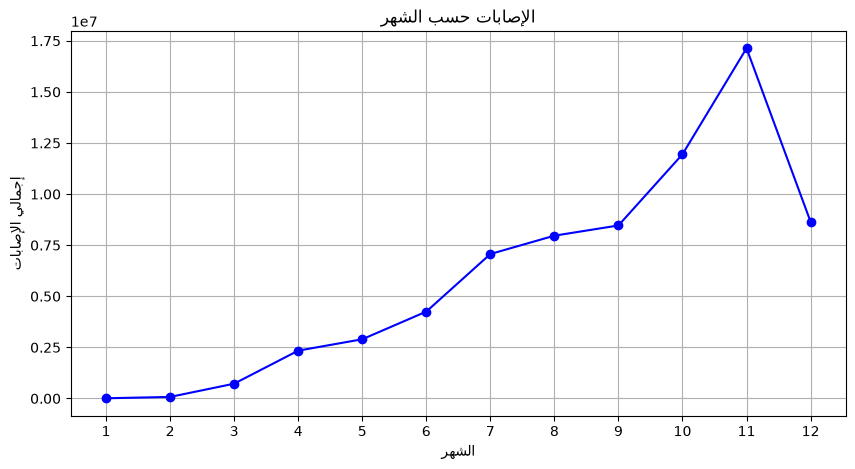

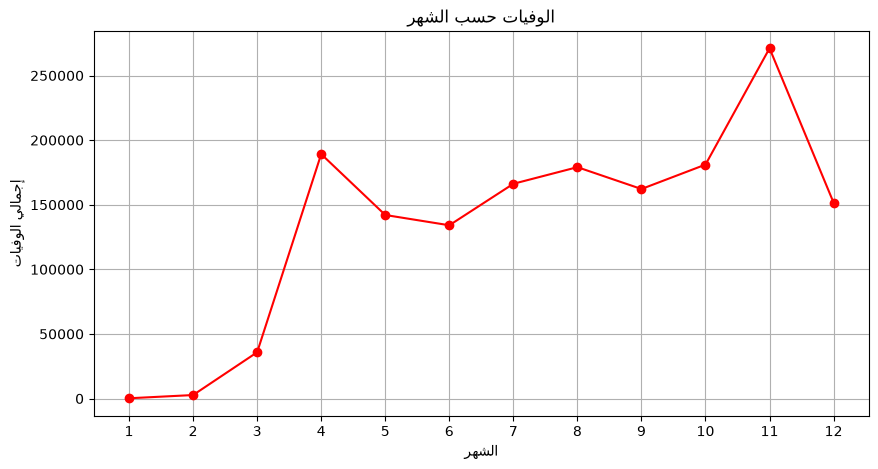

In [32]:
import matplotlib.pyplot as plt

# رسم الإصابات حسب الشهر
plt.figure(figsize=(10,5))
plt.plot(monthly_totals.index, monthly_totals['cases'], marker='o', linestyle='-', color='blue')
plt.title('الإصابات حسب الشهر')
plt.xlabel('الشهر')
plt.ylabel('إجمالي الإصابات')
plt.xticks(monthly_totals.index)
plt.grid(True)
plt.show()

# رسم الوفيات حسب الشهر
plt.figure(figsize=(10,5))
plt.plot(monthly_totals.index, monthly_totals['deaths'], marker='o', linestyle='-', color='red')
plt.title('الوفيات حسب الشهر')
plt.xlabel('الشهر')
plt.ylabel('إجمالي الوفيات')
plt.xticks(monthly_totals.index)
plt.grid(True)
plt.show()


In [33]:
countries_to_compare = ['Italy', 'China']


In [34]:
df_compare = df_cleaned[df_cleaned['Countries'].isin(countries_to_compare)]


In [35]:
monthly_country_totals = df_compare.groupby(['Countries', 'month'])[['cases', 'deaths']].sum().reset_index()


In [36]:
print(monthly_country_totals)


   Countries  month   cases  deaths
0      China      1    9687     213
1      China      2   69641    2624
2      China      3    2886     472
3      China      4    1703    1328
4      China      5     184       1
5      China      6     652       3
6      China      7    2709      18
7      China      8    2406      63
8      China      9     633      17
9      China     10     771       0
10     China     11     515       0
11     China     12     234       0
12     Italy      1       3       0
13     Italy      2     885      21
14     Italy      3  100851   11570
15     Italy      4  101852   16091
16     Italy      5   29073    5658
17     Italy      6    7920    1435
18     Italy      7    6722     388
19     Italy      8   21060     345
20     Italy      9   44793     398
21     Italy     10  334663    2446
22     Italy     11  937504   16583
23     Italy     12  258534    9616


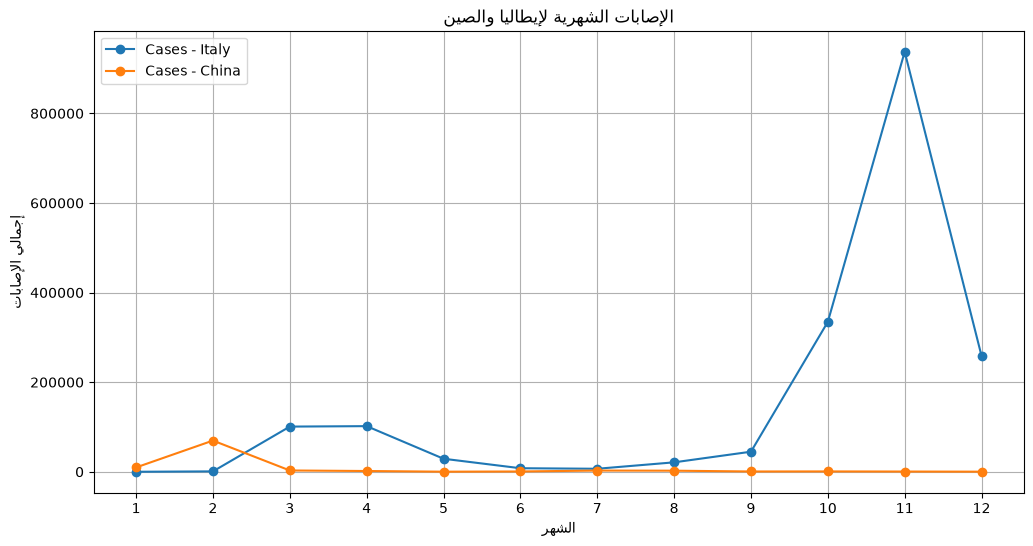

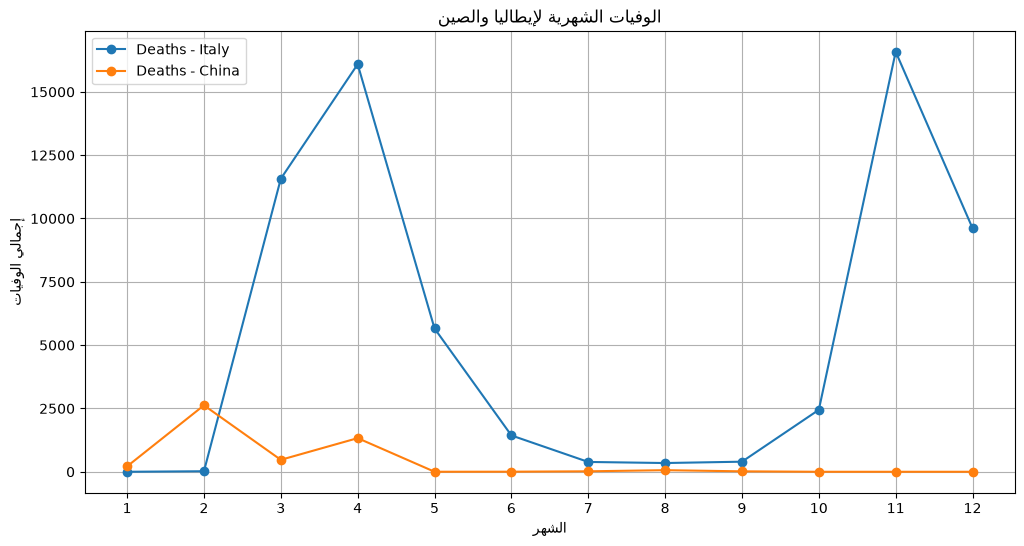

In [37]:
import matplotlib.pyplot as plt

# رسم الإصابات لكل دولة حسب الشهر
plt.figure(figsize=(12,6))
for country in countries_to_compare:
    data = monthly_country_totals[monthly_country_totals['Countries'] == country]
    plt.plot(data['month'], data['cases'], marker='o', label=f'Cases - {country}')
plt.title('الإصابات الشهرية لإيطاليا والصين')
plt.xlabel('الشهر')
plt.ylabel('إجمالي الإصابات')
plt.xticks(range(1,13))
plt.legend()
plt.grid(True)
plt.show()

# رسم الوفيات لكل دولة حسب الشهر
plt.figure(figsize=(12,6))
for country in countries_to_compare:
    data = monthly_country_totals[monthly_country_totals['Countries'] == country]
    plt.plot(data['month'], data['deaths'], marker='o', label=f'Deaths - {country}')
plt.title('الوفيات الشهرية لإيطاليا والصين')
plt.xlabel('الشهر')
plt.ylabel('إجمالي الوفيات')
plt.xticks(range(1,13))
plt.legend()
plt.grid(True)
plt.show()


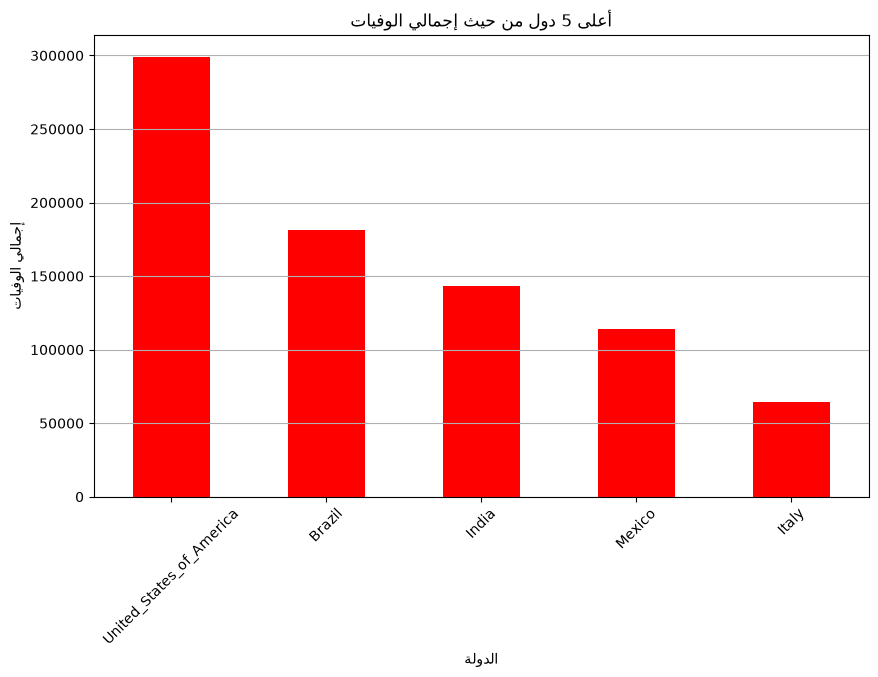

In [38]:
import matplotlib.pyplot as plt

# حساب إجمالي الوفيات لكل دولة
total_deaths_by_country = df_cleaned.groupby('Countries')['deaths'].sum()

# اختيار أعلى 5 دول من حيث إجمالي الوفيات
top_5_deaths = total_deaths_by_country.sort_values(ascending=False).head(5)

# رسم الرسم البياني
plt.figure(figsize=(10,6))
top_5_deaths.plot(kind='bar', color='red')
plt.title('أعلى 5 دول من حيث إجمالي الوفيات')
plt.xlabel('الدولة')
plt.ylabel('إجمالي الوفيات')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


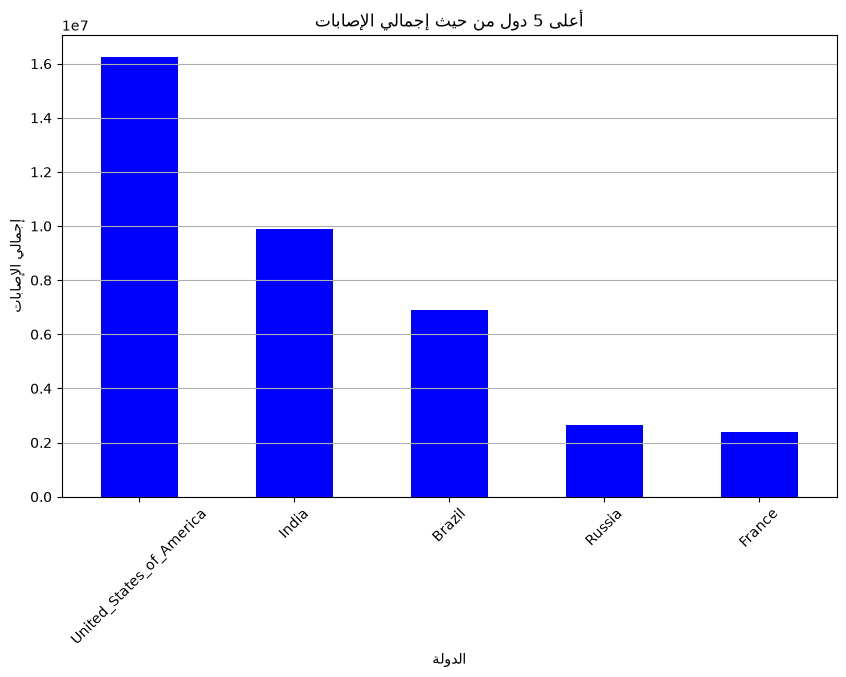

In [39]:
# حساب إجمالي الإصابات لكل دولة
total_cases_by_country = df_cleaned.groupby('Countries')['cases'].sum()

# اختيار أعلى 5 دول من حيث إجمالي الإصابات
top_5_cases = total_cases_by_country.sort_values(ascending=False).head(5)

# رسم الرسم البياني
plt.figure(figsize=(10,6))
top_5_cases.plot(kind='bar', color='blue')
plt.title('أعلى 5 دول من حيث إجمالي الإصابات')
plt.xlabel('الدولة')
plt.ylabel('إجمالي الإصابات')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.show()


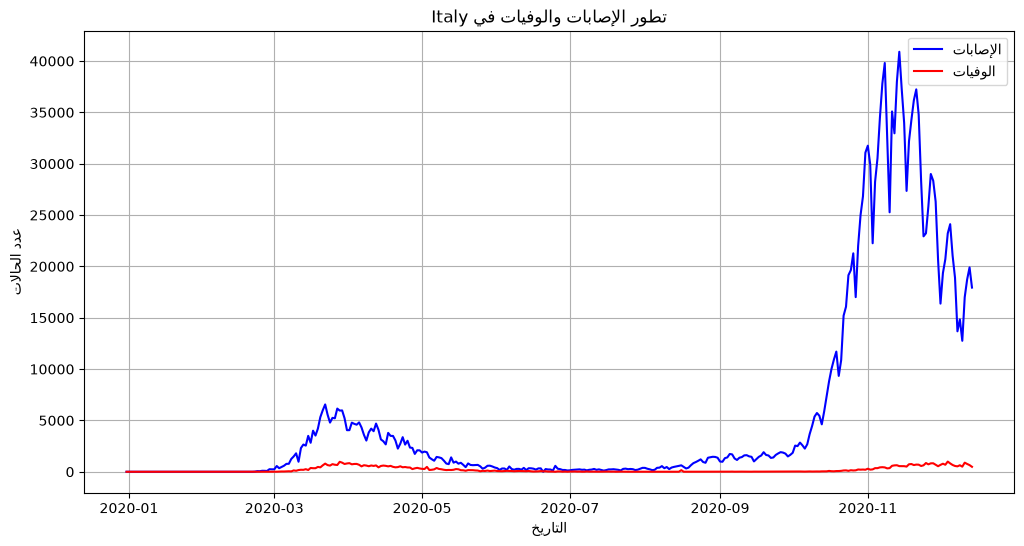

In [40]:
# اختر الدولة التي تريد تحليلها، مثلاً 'Italy'
selected_country = 'Italy'  # يمكنك تغييرها لأي دولة أخرى

# تصفية البيانات للدولة المختارة
df_country = df_cleaned[df_cleaned['Countries'] == selected_country]

# إنشاء عمود تاريخ إذا لم يكن موجودًا (من year, month, day)
if 'date' not in df_country.columns:
    df_country['date'] = pd.to_datetime(df_country[['year', 'month', 'day']])

# تجميع البيانات حسب التاريخ
daily_totals = df_country.groupby('date')[['cases', 'deaths']].sum()

# رسم الإصابات والوفيات عبر الزمن
plt.figure(figsize=(12,6))
plt.plot(daily_totals.index, daily_totals['cases'], label='الإصابات', color='blue')
plt.plot(daily_totals.index, daily_totals['deaths'], label='الوفيات', color='red')
plt.title(f'تطور الإصابات والوفيات في {selected_country}')
plt.xlabel('التاريخ')
plt.ylabel('عدد الحالات')
plt.legend()
plt.grid(True)
plt.show()


In [42]:
from ydata_profiling import ProfileReport  # أو from data_profiling import ProfileReport

# إنشاء التقرير الشامل للبيانات مع تمكين الوضع الاستكشافي
profile = ProfileReport(df, title="Diabetes Dataset Profile Report", explorative=True)

# عرض التقرير مباشرة داخل Jupyter Notebook كإطار iframe
profile.to_notebook_iframe()


C:\Users\su1tan\AppData\Local\Temp\ipykernel_19904\1226174093.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport  # أو from data_profiling import ProfileReport


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 12/12 [00:00<00:00, 13.15it/s][A


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [43]:
pip install ydata-profiling


Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

In [44]:
pip install pandas-profiling


  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  Getting requirements to build wheel did not run successfully.
  exit code: 1
  
  [27 lines of output]
  Traceback (most recent call last):
    File "C:\Users\su1tan\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 389, in <module>
      main()
      ~~~~^^
    File "C:\Users\su1tan\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 373, in main
      json_out["return_val"] = hook(**hook_input["kwargs"])
                               ~~~~^^^^^^^^^^^^^^^^^^^^^^^^
    File "C:\Users\su1tan\anaconda3\Lib\site-packages\pip\_vendor\pyproject_hooks\_in_process\_in_process.py", line 143, in get_requires_for_build_wheel
      return hook(config_settings)
    File "C:\Users\su1tan\AppData\Local\Temp\pip-build-env-qyyvwypm\overlay\Lib\site-packages\setuptools\build_meta.py", line 333, in get_requires_for_build_wheel
      return self._get_build_requires(config_settings, req